# Privacy Preserving Machine Learning Practical Session 2

Practical Session adapted from the Course of Aurélien Bellet

Course page: http://researchers.lille.inria.fr/abellet/teaching/private_machine_learning_course.html

<div style="text-align: right"> 
Sorbonne Université, MS2A, Master 2
</div>

## Goal of the practical session 

In our previous practical sessions, we highlighted the vulnerabilities of ad hoc, non-theoretically grounded privacy solutions. To overcome these limitations, in today’s session we introduce differential privacy, a rigorous and principled framework designed to ensure privacy-preserving data analysis. This concept which will serve as the foundation for the remainder of the course. The objective of this session is to explore the core concepts of differential privacy, along with its fundamental building blocks: the randomized response mechanism, the Laplace mechanism, the Gaussian mechanism, and the exponential mechanism. These mechanisms provide the essential tools for constructing strong privacy-preserving data analysis solutions.


## Table of contents
1. [Part 1: Introduction to differential privacy](#part0)
    - [Question 1 (Calculating $\epsilon$ and $\delta$ for the randomized mechanism)](#part0sec1)
    - [Question 2 (A different scheme)](#part0sec2)
    - [Question 3 (Implementing the randomized response)](#part0sec3)
    - [Question 4 (Working with private data)](#part0sec4)
1. [Part 2: Differential privacy for numeric queries](#part1)
    - [Question 1 (non-private queries)](#part1sec1)
    - [Question 2 (Laplace mechanism)](#part1sec2)
    - [Question 3 (Laplace mechanism on count queries)](#part1sec3)
    - [Question 4 (Laplace mechanism on average queries)](#part1sec4)
    - [Question 5 (average over a subset)](#part1sec5)
    - [Question 6 (Gaussian mechanism and comparison with Laplace)](#part1sec6)
1. [Part 3: Differential privacy for non-numeric queries](#part2)
    - [Question 1 ("Most common" query)](#part2sec1)
    - [Question 2 (Exponential mechanism)](#part2sec2)
    - [Question 3 (Exponential mechanism on "most common" queries)](#part2sec3)
    - [Question 4 (Exponential mechanism for model selection)](#part2sec4)

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml  # need sklearn >= 0.22
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.svm import SVC

# Part 1: Introduction to differential privacy <a id="part0"></a>


Among the numerous definition of private data analysis, differential privacy has become the dominant standard by providing a formal and adaptive conception of safe data-analysis. It states that an algorithm is  differentially private if, given two **close** databases, it produces statistically indistinguishable outputs.
Formally, a randomized mechanism $M$ is $(\epsilon, \delta)$-differentially private if for any output $S$ and for any two close databases $D$ and $D'$, $$\mathbb{P}[M(D) \in S] \leq e^{\epsilon} \mathbb{P}\left[M(D') \in S\right]. \text{   } (1)$$

$\epsilon$  and $\delta$ are the parameters that describes how much information is leaked by the function $M$. This might still sound a bit abstract, so let’s ground it in a concrete example. Suppose we want to create a privacy-preserving version of the Adult dataset from our first session. However, the potential adversary that will attack our database has extensive side information: they know almost the entire dataset except for one record, which could belong to Alice or Bob. Our goal is to ensure that Alice’s sensitive attribute (specifically, whether her income exceeds $50k$) remains indistinguishable from Bob’s, preventing the adversary from inferring too much about her data.Differential privacy achieves this by evaluating how the dataset changes before and after Alice’s inclusion, quantifying the privacy loss using the framework defined in equation (1). 

Consider a mechanism $M$ that deterministically outputs the count of individuals earning over $50k. If we run $M$ before and after adding Alice’s record, the difference in output would reveal her income with certainty. This illustrates why deterministic methods are fundamentally insecure: they directly expose sensitive information. To mitigate this risk, we introduce a curator, i.e., a trusted intermediary that injects controlled randomness into the process. This randomness is crucial for preserving privacy. Let’s now explore a simple yet effective technique for achieving this: randomized response.

* With probability $1-p$, we add a Alice's true income value to the database.
* With probability $p$ we choose a random boolean (0/1) value from Bernouilli distribution with parameter $q$ and add that value to the database instead.

**We denote 0/1 for generality, but for our application 1 means "income > 50k" and 0 means "income =< 50k"**

Using this scheme, an attacker cannot know with certainty if the real attribute value of Alice or a random one was added to the database. This protects the privacy of Alice but of course it also adds noise to the database, making it more difficult to use for legitimate users as well. In practice, we therefore always need to weigh privacy against utility when employing differential privacy. In this sectuion, we will compute the $\epsilon$, $\delta$ and other relevant parameters for our scheme above and see how we can use this differentially private data to make predictions about the income distribution of the people in our dataset.

## Question 1 (Calculating $\epsilon$ and $\delta$ for the randomized mechanism) <a id="part0sec1"></a>

Show that for any $\delta >0$, the randomized mechanism described above satisfies $(\epsilon, \delta)$-differential privacy with $$\epsilon = \ln \left (\text{max}\left\{ 1 + \frac{(1-p)}{p\times q} , \frac{1 -p\times q}{ p - p\times q}\right\} \right). $$

-  To your point of view, what value of $\epsilon$ represent a good enough uncertainty for the adversary? 
-  How does the level of privacy evolve when $\epsilon$ gets bigger/smaller? How would you choose $\delta$ ?  
-  Same question for the accuracy of $M$ (randomized response).
-  Write a function ``epsilon``that returns the value of epsilon for a given $p$ and $q$.
-  Plot the value of $\epsilon$ for various values of $p$ and $q$ and analysze the results.

In [33]:
def epsilon(p, q):
    """
    Parameters
    ----------
    p: 
        The probability of returning a random value instead of the true one
    q: 
        The probability of returning 1 when generating a random value
    
    Returns
    ----------
    epsilon: 
        The epsilon for the given values of p, q
    """
    # TO COMPLETE 
    if p <= 0 or p >= 1 or q <= 0 or q >= 1:
        return np.nan

    r1 = ((1 - p) + p*q) / (p*q)          # ratio for output=1
    r0 = (1 - p*q) / (p*(1 - q))          # ratio for output=0

    return np.log(max(r1, 1/r1, r0, 1/r0))

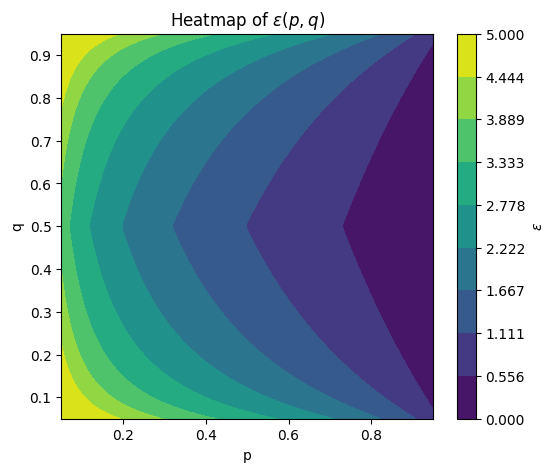

In [38]:
ps = np.linspace(0.05, 0.95, 100)
qs = np.linspace(0.05, 0.95, 100)

E = np.zeros((len(ps), len(qs)))

for i, p in enumerate(ps):
    for j, q in enumerate(qs):
        E[i, j] = epsilon(p, q)

E = np.clip(E, 0, 5)

Q, P = np.meshgrid(qs, ps, indexing="xy")

plt.figure(figsize=(6,5))

levels = np.linspace(0, 5, 10)

cont = plt.contourf(P, Q, E,
                    levels=levels,
                    cmap="viridis")

plt.colorbar(cont, label=r"$\epsilon$")
plt.xlabel("p")
plt.ylabel("q")
plt.title(r"Heatmap of $\epsilon(p,q)$")
plt.show()

## Question 2: (A different scheme) <a id="part0sec2"></a>

Let's assume we propose the following anonymization scheme for our dataset:

* With probability $1-p$, we add a person's true attribute value to the database
* With probability $p$, we do not add anything to the database

Can you compute the $\epsilon$ of this scheme? Which scheme do you prefer, and why? Does this scheme always provide "plausible deniability"?


With probability $1-p$, the true value is released. with probability $p$, nothing is released.
This scheme does not satisfy $\epsilon$-differential privacy with finite $\epsilon$.
For two neighboring datasets, the event “a value is released” has probability $1-p$ in one case
and $0$ in the other, which leads to an infinite privacy loss ($\epsilon=\infty$), unless $p=1$.

Randomized response is preferable since it always produces an output and provides a finite
privacy guarantee.

This scheme does not always provide plausible deniability: when a value is released,
the true attribute is revealed with certainty.


## Question 3 (Implementing the randomized response) <a id="part0sec3"></a>

Now that we have a feeling for our scheme we can implement it. For that, we load the "adult census" data from the k-anonymity case study again. You can read about the dataset [here](https://archive.ics.uci.edu/ml/datasets/census+income). The following line loads the dataset from a text file in `pandas DataFrame` format: this keeps the attributes in their original form and will be more convenient to work with. If you prefer working with a numpy array, set `as_frame=False` but it is not recommended in general.

In [11]:
names = (
    'age',
    'workclass', #Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked.
    'fnlwgt', # "weight" of that person in the dataset (i.e. how many people does that person represent) -> https://www.kansascityfed.org/research/datamuseum/cps/coreinfo/keyconcepts/weights
    'education',
    'education-num',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'capital-gain',
    'capital-loss',
    'hours-per-week',
    'native-country',
    'income',
)
categorical = set((
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'sex',
    'native-country',
    'race',
    'income',
))
df = pd.read_csv("adult.all.txt", sep=", ", header=None, names=names, index_col=False, engine='python');# We load the data using Pandas

Implement a function ``process_value`` that processes a new value according to the differentially private scheme discussed above. Use this function apply this method to the "income" column of the adult dataset to obtain a differentially private dataset e.g with p=q=0.5.

In [12]:
def process_value(value, p, q):
    """
    Parameters
    ----------
    value: 
        The value to apply the differentially private scheme to.
    p: 
        The probability of returning a random value instead of the true one
    q: 
        The probability of returning 1 when generating a random value
    
    Returns
    ----------
    dp_val: 
        A new, differentially private value
    """
    # TO COMPLETE 
    if np.random.rand() < p:
        return np.random.binomial(1, q)
    # With probability 1-p, return the true value
    else:
        return value
    pass

# ---- Apply to the income column of Adult ----
p = 0.5
q = 0.5

df_dp = df.copy()

df_dp["income_bin"] = (df_dp["income"].str.strip() == ">50K").astype(int)

df_dp["income_dp"] = df_dp["income_bin"].apply(lambda v: process_value(v, p, q))

## Question 4 (Working with private data) 

After collecting the differentially private data, we want of course to make use of it! For example, we might want to estimate the probability of a person having an income > 50K based on the data we have collected, which we assume is a Bernoulli distributed with a probability $\nu$ for every individual in the database. Now, when adding up the data from $n$ persons, the resulting value is binomially distributed. The mean of this distribution is given as $n\cdot \nu$ and the variance as $n\cdot \nu \cdot (1- \nu)$. A consistent and unbiased estimator of $\nu$ is $\hat{\nu} = \frac{1}{n}\sum_{i=1}^n \text{income}_i$ where $\text{income}_i$ is the income variable of the $i$th individual in the database.

Now, if we apply randomized response on our dataset, the probability of obtaining a $1$ will change to $\nu_{dp} = (1-p)\times \nu + p\times q$. Therefore, an unbiased and consistent estimator of $\nu$ based on $\nu_{dp} := \frac{1}{n}\sum_{i=1}^n \text{income}_i^{dp}$ is given as
$$
\begin{equation}
\hat{\nu} = \frac{\hat{\nu}_{dp} - p\times q}{1-p}
\end{equation}
$$

Note that this naive estimator can return a negative probability, which can be avoided by using a more suitable method like a maximum likelihood estimator.

- Write a function ``estimator`` that computes the estimator for $\hat{\nu}$ based on a differentially private dataset with parameters $p$ and $q$.
- Write a function ``variance_estimator`` that estimates the variance of $\hat{\nu}$ and calculate its value for the case above.
- Repeat the data generation process $N$ (e.g. 500) times. For each resulting dataset, estimate $\hat{\nu}$ and store the value in a list, and plot these values as an histogram. What do you observe ? If an adversary had access to these $N$ different generations, do you think the privacy guarantees would still hold ? Explain your response.  

In [13]:
def estimator(nu_dp, p, q):
    """
    Parameters
    ----------
    nu_dp: 
        The empirical probability of income>50K of our DP dataset.
    p: 
        The p value of our DP scheme.
    q: 
        The q value of our DP scheme.

    Returns
    ----------
    estimate: 
        An estimate of p_1 of our DP dataset.
    """
    #TO COMPLETE
    return (nu_dp - p * q) / (1 - p)
    pass

In [14]:
def variance_estimator(nu_dp, n, p, q):
    """
    Parameters
    ----------
    nu_dp: 
        The estimates probability of our DP dataset.
    n: 
        The number of samples in our dataset.
    p: 
        The p value of our DP scheme.
    q: 
        The q value of our DP scheme.
    
    Returns
    ----------
    var: 
        An estimate of the variance of our DP dataset.
    """
    #TO COMPLETE
    return nu_dp * (1 - nu_dp) / (n * (1 - p)**2)
    pass

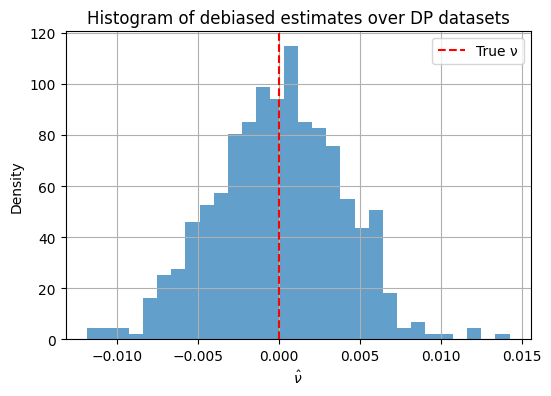

In [8]:
import matplotlib.pyplot as plt

p = 0.5
q = 0.5
N = 500
n = len(df)

if "income_bin" not in df.columns:
    df["income_bin"] = (df["income"].str.strip() == ">50K").astype(int)

nu_hats = []

for _ in range(N):
    income_dp = df["income_bin"].apply(lambda v: process_value(v, p, q))
    nu_dp = income_dp.mean()
    nu_hat = estimator(nu_dp, p, q)
    nu_hats.append(nu_hat)

nu_hats = np.array(nu_hats)

plt.figure(figsize=(6,4))
plt.hist(nu_hats, bins=30, density=True, alpha=0.7)
plt.axvline(df["income_bin"].mean(), color="red", linestyle="--", label="True ν")
plt.xlabel(r"$\hat{\nu}$")
plt.ylabel("Density")
plt.title("Histogram of debiased estimates over DP datasets")
plt.legend()
plt.grid(True)
plt.show()



**Histogram over $N$ runs: observation**

- The histogram of $\hat\nu$ is typically approximately bell-shaped (CLT), centered near the true $\nu$ (unbiasedness).
- The spread matches the variance above: larger $n$ or smaller $p$ $\Rightarrow$ narrower histogram; larger $p$ $\Rightarrow$ noisier, wider histogram.
- Because of debiasing, some samples of $\hat\nu$ can fall below 0 or above 1 (as noted), which can be fixed by clipping (post-processing).


**If an adversary sees $N$ independent generations, does DP still hold?**

Yes, but privacy degrades by composition.

- Each release is $\varepsilon$-DP.
- Releasing $N$ independent runs on the *same* underlying private dataset gives roughly $N\varepsilon$-DP under basic (sequential) composition.

So the guarantee still holds, but becomes weaker as $N$ grows.  
Intuitively, averaging many independent DP releases reduces noise and can reveal more about the true value, which is exactly captured by composition.

The histogram shows that the debiased estimates $\hat{\nu}$ follow a normal distribution centered on the true value $\nu$, confirming the estimator is unbiased. However, privacy guarantees would fail if an adversary accessed all $N$ generations because they could average the results to cancel out the noise and reconstruct the true data , while the privacy budget $\epsilon$ would accumulate linearly, effectively eliminating the protection of randomized response.

# Part 2: Differential privacy for numeric queries <a id="part1"></a>

## Reloading the Dataset

We will keep working with a dataset from the US Census (also known as the Adult dataset). But load it in a slightly different way (hence format). The following line loads the dataset from [OpenML](https://www.openml.org/) with the `fetch_openml` method of `sklearn`. The option `as_frame=True` (**requires sklearn version >= 0.22**) loads the dataset in `pandas DataFrame` format: this keeps the attributes in their original form and will be more convenient to work with. If you prefer working with a numpy array, set `as_frame=False` but it is not recommended in general.

In [2]:
dataset_handle = fetch_openml(name="adult", version=2, as_frame=True)
dataset = dataset_handle.frame

Take a look at the dataset, in particular the number of rows (individuals), the number of columns (attributes) and what they represent.

In [3]:
n, d = dataset.shape
print(n, d)
dataset.head(10)

48842 15


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,NaN,227026,HS-grad,9,Never-married,NaN,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


## Question 1 (non-private queries) <a id="part1sec1"></a>

Implement a function for each of these types of queries (without privacy) and test them on the dataset:
- **Simple count queries**: it takes as input a dataset (`DataFrame`), a categorical attribute (e.g., `"sex"`) and a value (e.g., `"Male"`), and returns how many rows in the dataset have the prescribed attribute value.
- **Averaging queries**: it takes as input a dataset and a numeric attribute (e.g., `"age"`), and returns the average value of this attribute in the dataset.
- **Histogram queries**: it takes as input a dataset and a categorical attribute (e.g., `"sex"`), and returns the histogram of counts for this attribute in the dataset (i.e., for each possible value of the attribute, how many rows have this value).

**Reminder:** for a DataFrame `df`, we can access the column corresponding to an attribute `attr` by `df[attr]`. The method `value_counts()` allows to build a histogram of a column. To plot a pandas Series `s` as a histogram, you can use `s.plot.bar()`.


In [4]:
def count_query(df, attribute, value, clip_value=None):
    """
    Parameters
    ----------
    df : DataFrame
        Dataset
    attribute : string
        Name of an attribute with categorical values
    value : string or int
        Value of attribute to count

    Returns
    -------
    count : int
        The number of records with `attribute=value` in dataset `df`
    """

# TO COMPLETE
    count = (df[attribute] == value).sum()
    
    if clip_value is not None:
        count = min(count, clip_value)
        
    return count
    pass # this is just to avoid error while the function is empty

In [5]:
def average_query(df, attribute, clip_value=None):
    """
    Parameters
    ----------
    df : DataFrame
        Dataset
    attribute : string
        Name of an attribute with numeric values

    Returns
    -------
    average : float
        The average value of `attribute` in dataset `df`
    """

# TO COMPLETE
    values = df[attribute]
    
    if clip_value is not None:
        values = values.clip(upper=clip_value)
        
    return values.mean()
    pass # this is just to avoid error while the function is empty

In [6]:
def histogram_query(df, attribute, clip_value=None):
    """
    Parameters
    ----------
    df : DataFrame
        Dataset
    attribute : string
        Name of an attribute with categorical values

    Returns
    -------
    histogram : array or Series of int
        The histogram of `attribute`, i.e., the number of times each value of `attribute` appears in `df`
    """

# TO COMPLETE
    hist = df[attribute].value_counts()
    
    if clip_value is not None:
        hist = hist.clip(upper=clip_value)
        
    return hist

    pass # this is just to avoid error while the function is empty

## Question 2 (Laplace mechanism) <a id="part1sec2"></a>

Implement the Laplace mechanism, i.e., a function which takes as input a (non-private) query output, the query's $\ell_1$ sensitivity, the desired value of $\epsilon$ and a random seed (for reproducibility), and returns a $\epsilon$-differentially private estimate of the query. To draw Laplace noise, check `np.random.laplace`. The function should work with queries that output a scalar (like simple count and averaging queries), as well as those that output a vector (like histogram queries).

In [7]:
def laplace_mechanism(q, s1, eps, random_state=None):
    """
    Parameters
    ----------
    q : float or array/Series of float
        The non-private output of the query
    s1 : float
        The L1 sensitivity of the query
    eps : float
        Parameter epsilon of differential privacy
    random_state : int, optional (default=None)
        Random seed

    Returns
    -------
    private_q : float or array/Series of float
        An eps-DP evaluation of the query
    """


    rng = np.random.RandomState(random_state)
    scale = s1 / eps
    
    # TO COMPLETE
    if hasattr(q, 'shape'): # query output is multi-dimensional
        noise = rng.laplace(loc=0.0, scale=scale, size=q.shape)
        return q + noise 
        pass
    else: # query output is a scalar
        noise = rng.laplace(loc=0.0, scale=scale)
        return q + noise
        pass
        

## Question 3 (Laplace mechanism on count queries) <a id="part1sec3"></a>

We would like to use the Laplace mechanism to:
- privately count the number of males in the dataset
- generate a private histogram of the `"workclass"` attribute

What is the sensitivity of the query in each case?

Run the Laplace mechanism with different values of $\epsilon$ and compute the $\ell_1$-error with respect to the true (non-private) output to see the effect on the utility and compare with the formal error bound seen in the lecture. Recall that the mechanism is random, so unless you fix the seed you will get a different result at each execution. Visually compare the private and non-private histograms.

**Note:** you may round the outputs of the private mechanism to make them integers if you like. This can be considered as post-processing and thus preserves DP.

### Sensitivity

### 1) Counting the number of males
Query: $f(D)=\#\{\text{male}\}$ (a single count).

Changing one individual can change the count by at most $1$, so:
$$
\Delta_1 f = 1.
$$

### 2) Histogram of "workclass"
Query: $f(D)\in\mathbb{R}^k$ where $f_j(D)$ is the count in bin/category $j$.

Changing one individual moves at most 1 count from one bin to another (or adds/removes one in add/remove adjacency). In either case the histogram changes in $\ell_1$ norm by at most $2$, so:
$$
\Delta_1 f = 2.
$$

--- Task 1: Private Count (Sex=Male) ---
True Male Count: 32650
Epsilon: 0.001  | Private Count: 32361    | L1 Error: 289
Epsilon: 0.01   | Private Count: 32621    | L1 Error: 29
Epsilon: 0.1    | Private Count: 32647    | L1 Error: 3
Epsilon: 1.0    | Private Count: 32650    | L1 Error: 0

--- Task 2: Private Histogram (Workclass) ---


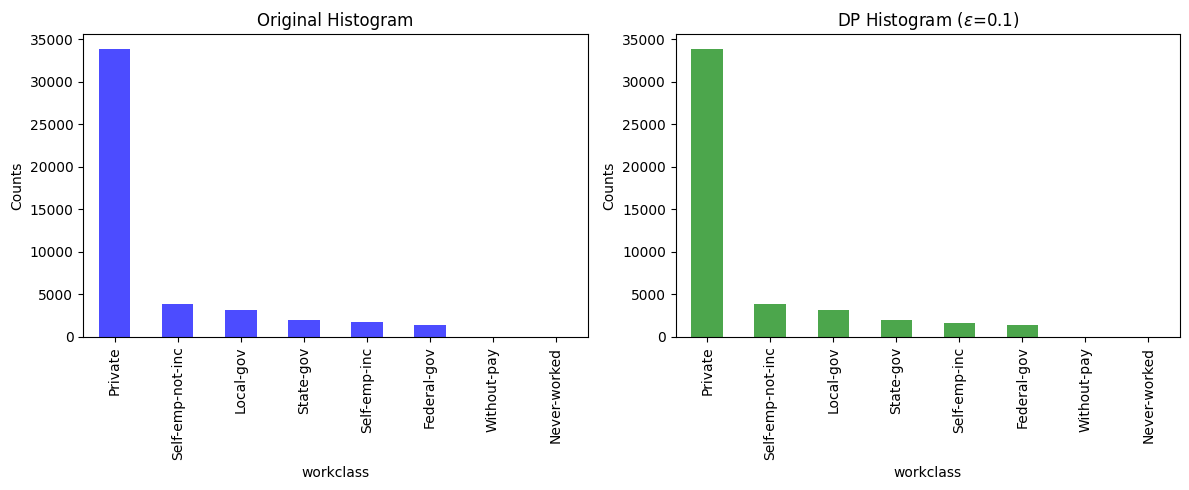

Epsilon: 0.001  | Total L1 Error: 9249.51
Epsilon: 0.01   | Total L1 Error: 924.95
Epsilon: 0.1    | Total L1 Error: 92.50
Epsilon: 1.0    | Total L1 Error: 9.25


In [8]:
def l1_error(a, b):
    """
    Parameters
    ----------
    a : float or array/Series of float
        First input
    b : float or array/Series of float
        Second input

    Returns
    -------
    l1_error : float
        The L1 distance between `a` and `b`: ||a-b||_1
    """

    # TO COMPLETE
    return np.sum(np.abs(np.array(a) - np.array(b)))


epsilon_values = [0.001, 0.01, 0.1, 1.0]
sensitivity = 1.0  

# Privately count the number of males
print("--- Task 1: Private Count (Sex=Male) ---")
true_male_count = count_query(dataset, "sex", "Male")
print(f"True Male Count: {true_male_count}")

for eps in epsilon_values:
    private_count = laplace_mechanism(true_male_count, sensitivity, eps, random_state=42)
    private_count_rounded = int(round(private_count))
    
    err = l1_error(true_male_count, private_count_rounded)
    print(f"Epsilon: {eps:<6} | Private Count: {private_count_rounded:<8} | L1 Error: {err}")

# Private Histogram of "workclass"
print("\n--- Task 2: Private Histogram (Workclass) ---")
true_hist = histogram_query(dataset, "workclass")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
true_hist.plot.bar(alpha=0.7, color='blue', title="Original Histogram")
plt.ylabel("Counts")

eps_hist = 0.1
private_hist = laplace_mechanism(true_hist, sensitivity, eps_hist, random_state=42)
private_hist_cleaned = private_hist.apply(lambda x: int(max(0, round(x))))

plt.subplot(1, 2, 2)
private_hist_cleaned.plot.bar(alpha=0.7, color='green', title=f"DP Histogram ($\epsilon$={eps_hist})")
plt.ylabel("Counts")

plt.tight_layout()
plt.show()

for eps in epsilon_values:
    p_hist = laplace_mechanism(true_hist, sensitivity, eps, random_state=42)
    err = l1_error(true_hist, p_hist)
    print(f"Epsilon: {eps:<6} | Total L1 Error: {err:.2f}")

## Question 4 (Laplace mechanism on average queries) <a id="part1sec4"></a>

We would like to use the Laplace mechanism to privately estimate the average age of people in the dataset. We assume that the number of people in the dataset is public.

1. Propose and implement simple practical strategies to compute or estimate the sensitivity of this query in the following two scenarios, and discuss the merits and/or drawbacks of your proposals:
      - You are the trusted curator: you have access to the raw dataset and would like to release an estimate of the average age of people in the dataset with differential privacy guarantees.
      - You are an external data analyst: you do not have access to the raw dataset but only to an API to send queries. You have to convince the trusted curator that the proposed sensitivity is safe.
2. Suggest some ideas regarding how we could change a bit the query to get a simple and safe bound on sensitivity, at the expense of possibly introducing some bias in the output. Implement the proposed solution. Hint: the method `clip` from pandas might be useful here.

### 1) Sensitivity of the mean in two scenarios

for the mean query $\bar{x}=\frac{1}{n}\sum_{i=1}^n x_i$, if we can guarantee that all values lie in $[L,U]$,
then the $\ell_1$ sensitivity is
$$
\Delta_1(\bar{x})=\frac{U-L}{n}.
$$

#### (a) Trusted curator 
A simple practical strategy is to *enforce* a public bound on ages by clipping:
$x_i^{clip}=\min(\max(x_i,L),U)$, then release the mean of clipped ages.
This gives a *data-independent* sensitivity bound $\Delta_1=(U-L)/n$.

**Merits:** safe and simple DP guarantee; sensitivity does not depend on the actual dataset.  
**Drawbacks:** introduces bias if some ages exceed the chosen bounds.

#### (b) External data analyst
Since the analyst cannot inspect raw ages, they must propose a conservative bound that is valid for all possible datasets,
e.g. human age in $[0,120]$ (or a policy bound enforced by the curator).
Then $\Delta_1=(U-L)/n$ is guaranteed safe.

**Merits:** always safe and easy to justify.  
**Drawbacks:** conservative bounds increase noise and reduce utility.

### 2) Modify the query to get a safe bound (clipping)
We clip ages to $[L,U]$ before averaging. This guarantees $\Delta_1=(U-L)/n$ but may introduce bias.

### 3) Average age of divorced people
Let $m$ be the number of divorced people. If $m$ is treated as public, we can apply the same idea on the subset:
$$
\Delta_1=\frac{U-L}{m}.
$$
Then we add Laplace noise with scale $\Delta_1/\varepsilon$ to the clipped mean on the divorced subset.


## Question 5 (Average over a subset) <a id="part1sec5"></a>

We would now like to compute the average age of divorced people. How can we use the Laplace mechanism to privately answer this query? Implement your solution.

In [9]:
age_clip_value = 70
avg = average_query(
    dataset[dataset["marital-status"] == "Divorced"], "age", age_clip_value
)
avg_dp = laplace_mechanism(avg, age_clip_value / n, 0.01)

print(f"Real average: {avg:.1f}")
print(f"DP average using Laplace: {avg_dp:.1f}")

Real average: 43.1
DP average using Laplace: 43.2


To privately compute the average age of divorced people:

1. Select individuals with marital-status = ‘Divorced’.
2. Clip ages to a public interval $[L, U]$ to bound sensitivity.
3. Compute the mean of the clipped ages.
4. Add Laplace noise with scale
   $$
   \frac{U-L}{m\varepsilon}
   $$
   where $m$ is the number of divorced individuals.


In [15]:
import numpy as np

# parameters
L = 0
U = 70
eps = 0.01

div = df[df["marital-status"] == "Divorced"]

m = len(div)  
if m == 0:
    print("No divorced individuals in dataset.")
else:
    clipped_age = div["age"].clip(lower=L, upper=U)
    real_avg = clipped_age.mean()
    s1 = (U - L) / m
    noise = np.random.laplace(loc=0.0, scale=s1/eps)

    dp_avg = real_avg + noise

    print(f"Number of divorced individuals: {m}")
    print(f"Real clipped average age: {real_avg:.2f}")
    print(f"DP average age (Laplace): {dp_avg:.2f}")

Number of divorced individuals: 6633
Real clipped average age: 43.11
DP average age (Laplace): 43.33


## Question 6 (Gaussian mechanism and comparison with Laplace) <a id="part1sec6"></a>

Implement the Gaussian mechanism (to draw Gaussian noise, check `np.random.normal`). Make an experimental comparison with the Laplace mechanism by plotting the privacy-utility trade-off for a 1D query of your choice. For the Gaussian mechanism, study the influence of $\delta$.

In [16]:
def gaussian_mechanism(q, s2, eps, delta, random_state=None):
    """
    Parameters
    ----------
    q : float or array/Series of float
        The non-private output of the query
    s2 : float
        The L2 sensitivity of the query
    eps : float
        Parameter epsilon of differential privacy
    delta : float
        Parameter delta of differential privacy
    random_state : int, optional (default=None)
        Random seed

    Returns
    -------
    private_q : float or array/Series of float
        An (eps,delta)-DP evaluation of the query
    """

    rng = np.random.RandomState(random_state)
    sigma = s2 * np.sqrt(2 * np.log(1.25 / delta)) / eps
    
    # TO COMPLETE
    if hasattr(q, 'shape'): # query output is multi-dimensional
        noise = rng.normal(0.0, sigma, size=q.shape)
        return q + noise
    else: # query output is a scalar
        noise = rng.normal(0.0, sigma)
        return q + noise

In [18]:
L, U = 0, 70
n = len(df)

clipped_age = df["age"].clip(L, U)
q = clipped_age.mean()

s1 = (U - L) / n   # L1 sensitivity
s2 = (U - L) / n   # L2 sensitivity 

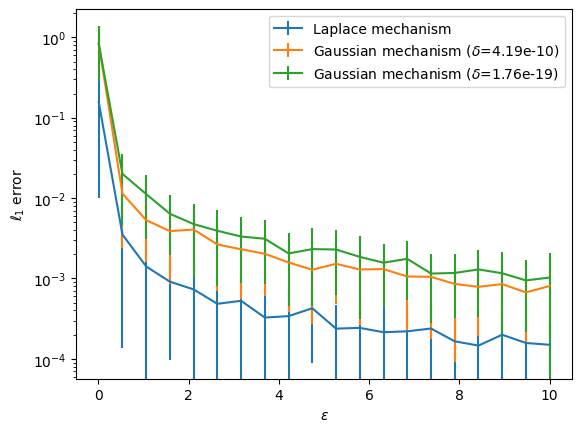

In [19]:
# q = 
# s = 
eps_list = np.linspace(0.01, 10.0, num=20)
delta1 = 1. / n**2
delta2 = 1. / n**4
n_runs = 50

error = np.zeros((len(eps_list), 3, n_runs))

for i, eps in enumerate(eps_list):
    for r in range(n_runs):
        q_lap = laplace_mechanism(q, s1, eps)
        error[i, 0, r] = abs(q_lap - q)
        
        q_g1 = gaussian_mechanism(q, s2, eps, delta1)
        error[i, 1, r] = abs(q_g1 - q)
        
        q_g2 = gaussian_mechanism(q, s2, eps, delta2)
        error[i, 2, r] = abs(q_g2 - q)
    
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.errorbar(eps_list, error[:, 0, :].mean(axis=1), error[:, 0, :].std(axis=1), label='Laplace mechanism')
ax.errorbar(eps_list, error[:, 1, :].mean(axis=1), error[:, 1, :].std(axis=1),
            label='Gaussian mechanism ($\delta$=' + "{:.2e}".format(delta1) + ')')
ax.errorbar(eps_list, error[:, 2, :].mean(axis=1), error[:, 2, :].std(axis=1),
            label='Gaussian mechanism ($\delta$=' + "{:.2e}".format(delta2) + ')')
plt.xlabel("$\epsilon$")
plt.ylabel("$\ell_1$ error")
ax.set_yscale('log')
ax.legend()

## Bonus Question 1 (Vulnerabilities from subtle implementation details)

The implementation of private mechanisms in this practical are meant to illustrate the main concepts seen in the lecture and the practical privacy-utility trade-offs that are achievable in practice. When deploying differential privacy in real-world production systems, utmost care must be taken to ensure that there is no unintended leakage of information that an adversary could exploit.

For instance, your implementation of private histogram queries is likely to suffer from subtle privacy leakages which can actually break the differential privacy guarantees! Can you identify some of them and suggest a way to fix them?

**Hint:** one potential problem is related to the order in which the values of the private histogram are given

## Bonus Question 2 (Linear queries)

For any dataset $D\in\mathbb{N}^d$ (i.e., seen as a histogram over the data domain $\mathcal{X}$ of size $d$), a linear query $f_A:\mathbb{N}^{|d|}\rightarrow\mathbb{R}^k$ parameterized by a (public) matrix $A\in\mathbb{R}^{k\times d}$ is defined by:

$$f_A(D) = AD = \begin{bmatrix}
           \sum_{j=1}^d A_{1,j}D_j \\
           \vdots \\
           \sum_{j=1}^d A_{k,j}D_j
         \end{bmatrix} \in\mathbb{R}^k$$

Linear queries are a generalization of some queries we have discussed earlier (such as count queries, sum queries and histogram queries), allowing to use arbitrary weights on the elements of the data domain $\mathcal{X}$.

We would like to apply the Gaussian mechanism to privately compute $f_A(D)$ for some $A\in\mathbb{R}^{k\times d}$. What is the $\ell_2$ sensitivity of $f_A$? Show that this general formula allows to recover the sensitivity obtained for count, sum and histogram queries.

# Part 3: Differential privacy for non-numeric queries <a id="part2"></a>

## Question 1 ("Most common" query) <a id="part2sec1"></a>

Implement a function for "most common" queries: it takes as input a dataset (`DataFrame`), an attribute (e.g., `"education"`), and returns the most common value of this attribute in the dataset (ties can be broken arbitrarily). Note that in general, the output of such queries is non-numeric. The pandas methods `value_counts`, `idxmax()` or `mode` can be useful here. Test your function on the dataset.

In [20]:
def most_common_query(df, attribute):
    """
    Parameters
    ----------
    df : DataFrame
        Dataset
    attribute : string
        Name of an attribute (with categorical values)

    Returns
    -------
    value : float or string
        The most common value of `attribute` in dataset `df`
    """

    # TO COMPLETE
    if attribute not in df.columns:
        raise ValueError(f"{attribute} not found in dataframe")

    counts = df[attribute].value_counts(dropna=False)
    
    # idxmax returns the index (category) with highest count
    return counts.idxmax()

## Question 2 (Exponential mechanism) <a id="part2sec2"></a>

Implement the exponential mechanism, i.e., a function which takes as input the list of possible outputs, the corresponding scores (assuming a numpy array format will be most convenient), the sensitivity of the score function, the desired value of $\epsilon$ and a random seed (for reproducibility), and returns an output selected in an $\epsilon$-differentially private way. To sample an ouput, use `numpy.random.choice`.

**Careful**: if you implement the exponential mechanism naively you will get numerical errors because un-normalized probabilities will quickly become very large. You should compute everything in log domain and only take the exponential at the end. To compute the normalization term in log domain, you can use `scipy.special.logsumexp`.

In [21]:
from scipy.special import logsumexp

def exponential_mechanism(outputs, scores, sensitivity, eps, random_state=None):
    """
    Parameters
    ----------
    outputs : list
        Possible outputs for the query
    scores : array of float
        Scores associated to each output
    sensitivity : float
        The sensitivity of the score
    eps : float
        Parameter epsilon of differential privacy
    random_state : int, optional (default=None)
        Random seed

    Returns
    -------
    private_q : float or string (sans as outputs)
        An eps-DP evaluation of the query
    """

    rng = np.random.RandomState(random_state)

    # TO COMPLETE
    scores = np.asarray(scores, dtype=float)
    if len(outputs) != scores.shape[0]:
        raise ValueError("outputs and scores must have the same length")
    if sensitivity <= 0:
        raise ValueError("sensitivity must be > 0")
    if eps <= 0:
        raise ValueError("eps must be > 0")

    log_w = (eps * scores) / (2.0 * sensitivity)


    log_Z = logsumexp(log_w)
    probs = np.exp(log_w - log_Z)

    idx = rng.choice(len(outputs), p=probs)
    return outputs[idx]

## Question 3 (Exponential mechanism on "most common" queries) <a id="part2sec3"></a>

We would like to use the exponential mechanism to privately answer the following queries:
- What is the most common level of education of people in the dataset?
- What is the most common occupation of people in the dataset?
- What is the most common age of people in the dataset?

Define an appropriate score function for these queries. What is the sensitivity of your score function?

Use the exponential mechanism to privately answer these queries for $\epsilon=0.1$ and several random executions. Compare the output to the non-private result, and explain why for some queries the true (non-private) output is returned more often.

### Score function and sensitivity

For each query (education, occupation, age), we use a frequency-based score.

Let $x$ be a candidate output.  
Define the score function as:

$$
u(D,x) = \#\{ i : \text{attribute}_i = x \}
$$

i.e., the number of records whose attribute equals $x$.


### Sensitivity

For two neighboring datasets $D$ and $D'$ differing by one record,  
the count of any category can change by at most 1. Therefore,

$$
\Delta u = \max_x |u(D,x) - u(D',x)| = 1.
$$


In [22]:
def private_most_common_query(df, attribute, eps, random_state=None):
    """
    Parameters
    ----------
    df : DataFrame
        Dataset
    attribute : string
        Name of an attribute (with categorical values)
    eps : float
        Parameter epsilon of differential privacy
    random_state : int, optional (default=None)
        Random seed

    Returns
    -------
    private_q : float or string
        An eps-DP evaluation of the "most common" query on `attribute`
    """
    
    # TO COMPLETE
    rng = np.random.RandomState(random_state)

    vc = df[attribute].value_counts(dropna=False)
    outputs = vc.index.to_list()
    scores = vc.values.astype(float)

    sensitivity = 1.0 

    log_w = (eps * scores) / (2 * sensitivity)
    log_Z = logsumexp(log_w)

    probs = np.exp(log_w - log_Z)
    idx = rng.choice(len(outputs), p=probs)

    return outputs[idx]


In [23]:
query_attribute = ['education', 'occupation', 'age']

for attr in query_attribute:
    print("\nAttribute queries:", attr)
    for r in range(20):
        print(private_most_common_query(dataset, attr, 0.1))


Attribute queries: education
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad
HS-grad

Attribute queries: occupation
Exec-managerial
Prof-specialty
Prof-specialty
Prof-specialty
Craft-repair
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty
Prof-specialty

Attribute queries: age
23
23
36
35
33
36
23
35
36
35
31
23
33
28
36
35
33
35
35
36


## Question 4 (Exponential mechanism for model selection) <a id="part2sec4"></a>

Suppose that you would like to build a model to predict the income of an individual based on its personal features (for instance, to study which features are predictive of income). You have access to a small *public* dataset of 50 people in the same format as the US Census dataset we have been working with so far, and you would like to train a classifier to predict whether an individual makes more than 50$/year from its personal features. However, there are hyper-parameters to tune and you know the dataset is too small to reliably estimate the generalization performance of each model to select the best.

There exists a larger dataset held by the US Census on which you could perform model selection, but this dataset is *private*. Therefore you would like to privately perform model selection on this dataset, i.e., among the set of models you trained on the small public dataset, you would like to select the one which performs best on the private dataset in an $\epsilon$-DP fashion.

To simulate this scenario, we use the same dataset as before. For convenience, we load it in numpy format where all categorical features have been coded as numerical variables, and remove the features that have missing values. We then split the full dataset into a small dataset with 50 people (the *public* dataset) and a larger dataset of 48K+ people (the *private* dataset).

In [32]:
X, y = fetch_openml(name="adult", version=2, return_X_y=True, as_frame=True)

X = X.replace('?', np.nan)

X = X.dropna()
y = y.loc[X.index]

num_cols = X.select_dtypes(include=["number"]).columns
cat_cols = X.select_dtypes(exclude=["number"]).columns

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

X_proc = preprocess.fit_transform(X)

X_public, X_private, y_public, y_private = train_test_split(
    X_proc, y, train_size=50, random_state=42
)

print(X_public.shape, y_public.shape, X_private.shape, y_private.shape)

(50, 104) (50,) (45172, 104) (45172,)


1. What is the output space of the query?
2. How to define the score function in this case? What is its sensitivity?
3. Implement a function for private model selection with the exponential mechanism: it takes as input the public and the private datasets, a scikit-learn model (e.g., `LogisticRegression()`), a `ParameterGrid` (see [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterGrid.html)) giving the possible hyper-parameters and values, the desired value of $\epsilon$ and a random seed (for reproducibility), and returns a set of hyper-parameters selected in an $\epsilon$-DP way.
4. Run this to tune the value of the parameter `C` of `LogisticRegression()`. You may also try other cases, e.g., tuning the choice of kernel, parameter `C` and parameter `gamma` of the RBF kernel in a SVM model.

### 1. Output space

The output space is the finite set of hyper-parameter configurations:

$$
\mathcal{R} = \{ \theta : \theta \in \texttt{ParameterGrid(grid)} \}.
$$


### 2. Score function and sensitivity

Choose validation accuracy on the private dataset:

$$
u(D_{\text{priv}}, \theta)
=
\frac{1}{n}
\sum_{i=1}^{n}
\mathbf{1}\{\hat y_\theta(x_i)=y_i\}
\in [0,1].
$$

#### Sensitivity

Changing one example affects at most one term:

$$
\Delta u = \frac{1}{n_{\text{priv}}}.
$$


### 3. Exponential mechanism 
Sample hyper-parameters with probability:

$$
\Pr(\theta)
\propto
\exp\left(
\frac{\varepsilon \, u(D_{\text{priv}}, \theta)}
{2 \Delta u}
\right).
$$

Here:

$$
\Delta u = \frac{1}{n_{\text{priv}}}.
$$

In [39]:
def private_model_selection(
    X_public, y_public, X_private, y_private, model, grid, eps, random_state=None
):
    """
    Parameters
    ----------
    X_public : array of shape (n1, d)
        Public dataset
    y_public : array of shape (n1,)
        Public labels
    X_private : array of shape (n2, d)
        Private dataset
    y_private : array of shape (n2,)
        Private labels
    model : BaseEstimator
        An instance of a scikit-learn model
    grid : ParameterGrid
        A grid describing the set of hyperparameters to tune and their possible values
    eps : float
        Parameter epsilon of differential privacy
    random_state : int, optional (default=None)
        Random seed

    Returns
    -------
    private_best_params : dict
        An eps-DP evaluation of best hyperparameter search
    """

    n_private = X_private.shape[0]
    accuracies = np.zeros(len(grid))
    for i, param in enumerate(grid):
        model.set_params(**param)
        # TO COMPLETE
        model.fit(X_public, y_public)
        accuracies[i] = model.score(X_private, y_private)  # in [0,1]

    # Exponential mechanism (utility = accuracy, sensitivity = 1/n_private)
    delta_u = 1.0 / n_private

    rng = np.random.default_rng(random_state)

    logits = (eps * accuracies) / (2.0 * delta_u)  # = eps * accuracies * n_private / 2
    logits -= np.max(logits)  # numerical stability

    probs = np.exp(logits)
    probs /= probs.sum()

    idx = rng.choice(len(grid), p=probs)
    private_best_params = list(grid)[idx]
    return private_best_params

In [40]:
params = {"C": np.geomspace(1e-3, 1e3, num=100)}
grid = ParameterGrid(params)
model = LogisticRegression(solver="liblinear")
# TO COMPLETE

eps = 1.0
best_params_lr = private_model_selection(
    X_public, y_public, X_private, y_private, model, grid, eps, random_state=42
)
print("DP-selected params (LogReg):", best_params_lr)

model.set_params(**best_params_lr)
model.fit(X_public, y_public)
print("Private accuracy (LogReg):", model.score(X_private, y_private))

DP-selected params (LogReg): {'C': np.float64(0.06579332246575682)}
Private accuracy (LogReg): 0.8201540777472771


In [41]:
params = [
    {
        "kernel": ["rbf"],
        "gamma": np.geomspace(1e-4, 1e4, num=20),
        "C": np.geomspace(1e-3, 1e3, num=10),
    },
    {"kernel": ["linear"], "C": np.geomspace(1e-3, 1e3, num=10)},
]
grid = ParameterGrid(params)
model = SVC()
# TO COMPLETE
best_params_svm = private_model_selection(
    X_public, y_public, X_private, y_private, model, grid, eps, random_state=42
)
print("DP-selected params (SVM):", best_params_svm)

model.set_params(**best_params_svm)
model.fit(X_public, y_public)
print("Private accuracy (SVM):", model.score(X_private, y_private))

DP-selected params (SVM): {'C': np.float64(10.0), 'gamma': np.float64(0.004832930238571752), 'kernel': 'rbf'}
Private accuracy (SVM): 0.8094173381740901


## Bonus Question 1 (Laplace mechanism and Report Noisy Max)

1. Propose a simple way to privately answer the queries of Questions 3 and 4 using the Laplace mechanism instead of the exponential mechanism. What is the $\ell_1$ sensitivity for the two cases? For Question 4, do you think it is possible to do better with the Laplace mechanism?
2. Read about Report Noisy Max in Section 3.3 of [Dwork & Roth (2014)](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).